## Importing the libraries

In [3]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import re

## Load and Prepare Data

In [4]:
df = pd.read_csv("googleplaystore.csv")
df = df[df['App']!= 'Life Made WI-Fi Touchscreen Photo Frame'].reset_index(drop=True)
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## EDA

In [5]:
print(df.info())
print(df.describe())
print(df.shape)
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 10840 entries, 0 to 10839
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  str    
 1   Category        10840 non-null  str    
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  str    
 4   Size            10840 non-null  str    
 5   Installs        10840 non-null  str    
 6   Type            10839 non-null  str    
 7   Price           10840 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10840 non-null  str    
 10  Last Updated    10840 non-null  str    
 11  Current Ver     10832 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB
None
            Rating
count  9366.000000
mean      4.191757
std       0.515219
min       1.000000
25%       4.000000
50%       4.300000
75%       4.500000
max       5.000000
(1

## Data Preprocessing

In [6]:

# App Columm OK
#-------------------
# Category Columm OK
#---------------------
# Rating Columm (Outlier & Missing vslue (NaN))
#clean reting columm
def convert_rating(r):
    if pd.isna(r):
        #NaN = r (r = NaN)
        return(r)
    if(r <= 5):
        #[0,5] = r
        return(r)
    return(np.nan)

    
df['Rating'] = df['Rating'].apply(convert_rating)
#fill missing
rating_mean = df['Rating'].median()
df['Rating'] = df['Rating'].fillna(rating_mean)
#-----------------------------------------------
# Installs Columm 
def clean_installs(x):
    try:
        x = str(x).replace(',','').replace('+','').strip()
        if(x=='' or not x.isdigit()):
            return(0)    
        return(int(x))
    except:
        return(0)
df['Installs'] = df['Installs'].apply(clean_installs)
#------------------------------------------------------
# Price Column
# clean price column
def clean_price(x):
    x = str(x).replace('$', '').strip()
    if x == '' or x == 'Free':
        return 0.0
    try:
        return float(x)
    except:
        return 0.0

df['Price'] = df['Price'].apply(clean_price)
#--------------------------------------------------------------
#Reviews Columm
#str -> int
def clean_reviews(x):
    try:
        x = str(x).replace(',','').strip()
        if(x=='' or x=='Everyone' or not x.replace('.','').isdigit()):
           return(0)
        return(int(float(x)))
    except:
        return(0)

df['Reviews'] = df['Reviews'].apply(clean_reviews)
#--------------------------------------------------
#Seza Columm
def clean_size(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if('Varies with device' in x):
        return np.nan
    try:
        if 'M' in x:
            return(float(x.replace('M','').replace(',','')))
        if 'K' in x:
            return(float(x.replace('K','').replace(',',''))/1024)
        else:
            return(float(x))
    except:
        return np.nan  
df['Size'] = df['Size'].apply(clean_size)
size_median = df['Size'].median()
df['Size'] = df['Size'].fillna(size_median)
#-------------------------------------------
df['Main_Genre'] = df['Genres'].str.split(';').str[0]
#-------------------------------------------------------
df['Type'] = df['Type'].fillna(df['Type'].mode()[0])
#----------------------------------------------------------
df['Content Rating'] = df['Content Rating'].fillna(df['Content Rating'].mode()[0])
#-----------------------------------------------------------------------------------
#re
def extract_version_number(version):
    try:
        numbers = re.findall(r'(\d+\.\d+\.?\d*)', str(version))
        if numbers:
            return numbers[0]
        else:
            return '0'
    except:
        return '0'


df['Current Ver'] = df['Current Ver'].apply(extract_version_number)


df['Android Ver'] = df['Android Ver'].apply(extract_version_number)

#df['Current Ver'] = df['Current Ver'].fillna(df['Current Ver'].mode()[0])
#df['Android Ver'] = df['Android Ver'].fillna(df['Android Ver'].mode()[0])
#__________________________________________________________________________________________
#Didtinc Value
#print(f" sum colums: {df.shape[0]}")
#------------------------------------------
duplicates_all = df.duplicated().sum()
#print(f" duplicastes all: {duplicates_all}")
#--------------------------------------------
duplicates_app = df.duplicated(subset=['App']).sum()
#print(f"duplicates App: {duplicates_app}")
#-----------------------------------------------------
df = df.drop_duplicates()
#--------------------------
df = df.sort_values('Rating' , ascending=False).drop_duplicates(subset=['App'],keep='first')
#------------------------------------------------------------------------------------------------
df = df.reset_index(drop=True)
#________________________________________________________________________________________________
#check

print(df.shape[0])
print("------------------")
print(df.shape[1])
print("------------------")
print(df.isnull().sum().sum())
print("------------------")
print(df.dtypes)
print("------------------")

#df['Installs'].value_counts().head(30)
#df[['App','Installs']].head(20)
#print(df.isnull().sum())  
#df.head(500)
#________________________________________________________________________________________________
df.to_csv('googleplaystore_cleaned_1.0.0.csv',index=False)




9659
------------------
14
------------------
0
------------------
App                   str
Category              str
Rating            float64
Reviews             int64
Size              float64
Installs            int64
Type                  str
Price             float64
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
Main_Genre         object
dtype: object
------------------


## Strorytelling - Visualization

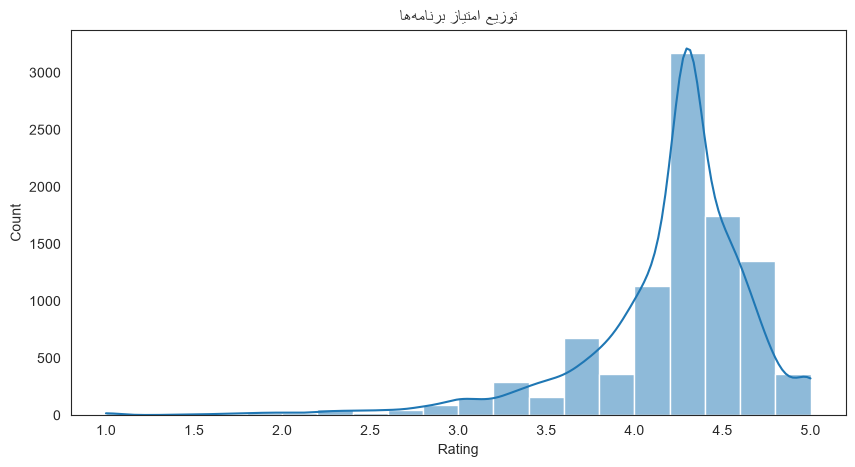

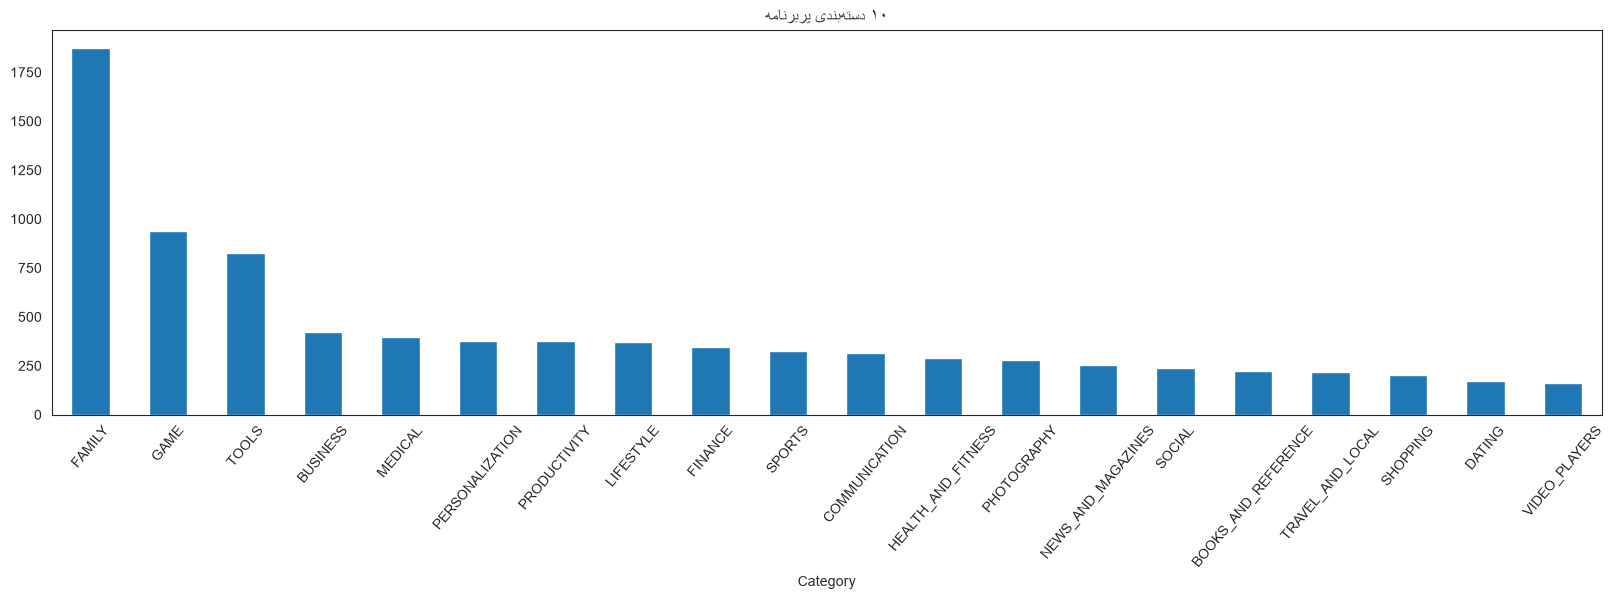

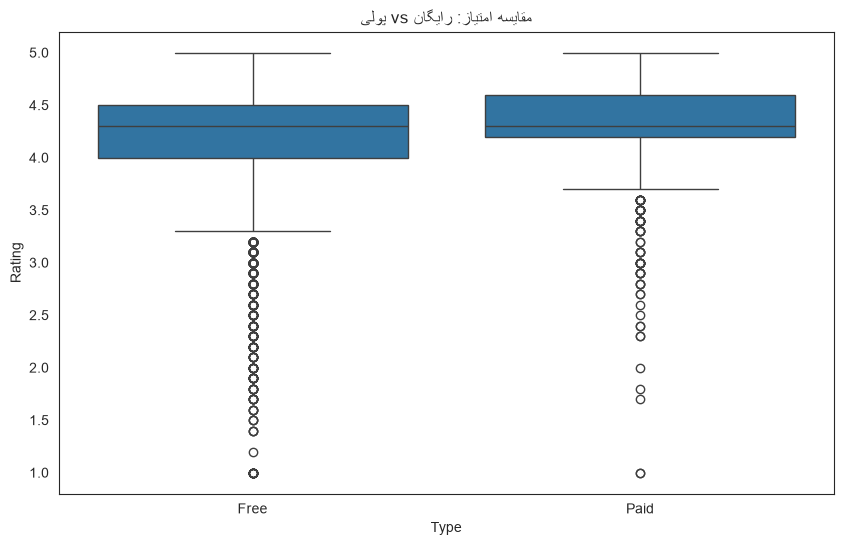

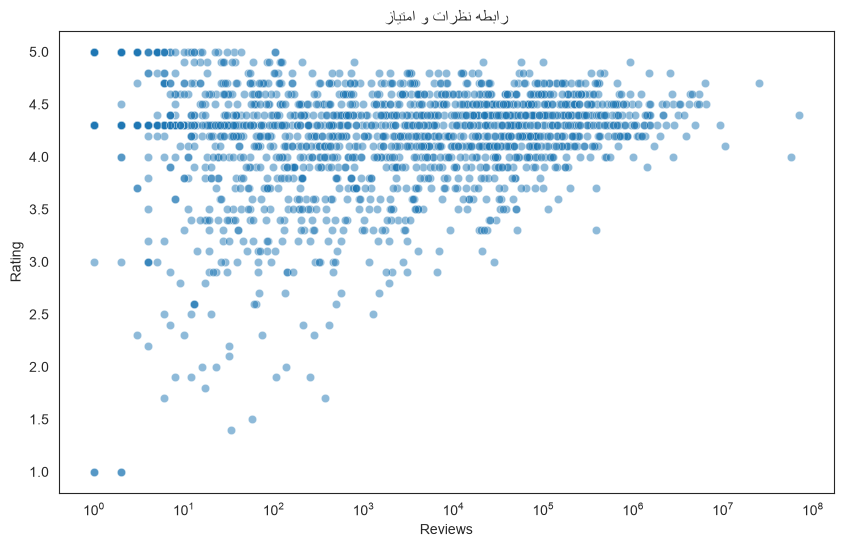

In [7]:
sns.set_style("white")

# ۱. توزیع امتیاز
plt.figure(figsize=(10, 5))
sns.histplot(df['Rating'], bins=20, kde=True)
plt.title('توزیع امتیاز برنامه‌ها')
plt.show()
#----------------------------------------------------------------------------------
# ۲. ۱۰ دسته‌بندی برتر
plt.figure(figsize=(20, 5))
df['Category'].value_counts().head(20).plot(kind='bar')
plt.title('۱۰ دسته‌بندی پربرنامه')
plt.xticks(rotation=50)
plt.show()
#----------------------------------------------------------------------------------
# ۳. مقایسه رایگان و پولی
plt.figure(figsize=(10, 6))
sns.boxplot(x='Type', y='Rating', data=df)
plt.title('مقایسه امتیاز: رایگان vs پولی')
plt.show()
#----------------------------------------------------------------------------------
# ۴. رابطه نظرات و امتیاز
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Reviews', y='Rating', data=df.sample(2000), alpha=0.5)
plt.xscale('log')
plt.title('رابطه نظرات و امتیاز')
plt.show()
#----------------------------------------------------------------------------------